# 04d - Clustering: perfis de mutuários

Agrupar os mutuários pelo perfil de crédito no momento do pedido, sem alvo: o algoritmo junta empréstimos parecidos e a leitura dos grupos é feita depois. O enunciado dá este exemplo: *"borrower clustering (FICO, DTI, credit age, utilization)"*.

São dois algoritmos, o k-means e a mistura de gaussianas (GMM), com o número de grupos a variar de 2 a 10. As medidas de avaliação estão em `src/lending/clustering.py` (`ClusterEvaluator`) e as variáveis e o pré-processamento na classe `BorrowerProfiles` do mesmo módulo.

| Requisito do enunciado | Onde |
|---|---|
| *"Apply at least two clustering algorithms"* | k-means e GMM |
| *"Vary their relevant hyperparameters, including the number of clusters"* | k de 2 a 10; no GMM também o tipo de covariância |
| *"Describe the resulting groups and assess their stability and interpretability"* | Perfis dos grupos e ARI entre sementes e entre amostras |
| *"For clustering, use appropriate internal measures alongside substantive interpretation"* | Cotovelo, silhueta, Davies-Bouldin e Dunn (implementado por nós) |

**Antes de correr:** `01_preprocessamento.ipynb` (gera `aceites_dev.pkl`).

In [1]:
# Setup: imports e caminhos do projeto
import sys
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lending import config
from lending.clustering import PROFILE_LABELS, BorrowerProfiles
from lending.plot_style import CATEGORICAL, DIVERGING_CMAP, apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

## 1. Dados e variáveis

**Coorte.** São os 466 124 empréstimos aceites de 2007-06 a 2014-12 (a coorte do clustering da Parte 1, sem filtros além da limpeza). Ao contrário da classificação, não é preciso conhecer o desfecho, por isso entram também os empréstimos ainda ativos (`Current`). O teste de 2015 nunca é usado: o clustering é descritivo e não tem avaliação final.

**Variáveis do ajuste** (perfil no momento do pedido):

| Variável | O que mede | Porquê |
|---|---|---|
| `fico_range_low` | Pontuação de crédito | Exemplo do enunciado. O `fico_range_high` é sempre `low + 4`: as duas dariam o mesmo valor padronizado e o FICO contaria a dobrar |
| `dti` | Dívidas mensais / rendimento mensal (%) | Exemplo do enunciado |
| `revol_util` | % do limite rotativo em uso | "Utilização" do enunciado |
| `annual_inc` | Rendimento anual | Capacidade financeira |
| `loan_to_income` | Montante pedido / rendimento | Esforço do pedido |
| `revol_to_income` | Saldo rotativo / rendimento | Dívida de cartões face ao rendimento (o `revol_util` não o diz) |
| `open_acc_pct` | % das contas do historial ainda abertas | Crédito recente ou acumulado |
| `credit_history_years` | Anos desde a primeira linha de crédito até à concessão | "Credit age" do enunciado |

A antiguidade do crédito usa o `issue_d` como data de referência. Na tabela de elegibilidade da Fase 1 o `issue_d` estava ❌ no clustering; passou a ⚠️, só como referência desta feature (como já acontecia na classificação).

**Fora do ajuste:** as binárias `ever_delinquent` e `has_public_record` só descrevem os grupos. A taxa de juro, o grau e o desfecho também ficam de fora: são usados depois, para dar significado de negócio aos grupos, e não podem influenciar a sua formação.

In [2]:
data = PickleStore.load(config.ACCEPTED_DEV_PKL, expected_type=pd.DataFrame)
print(f"{len(data):,} empréstimos, {data['issue_d'].min():%Y-%m} a {data['issue_d'].max():%Y-%m}")

profiles = BorrowerProfiles()
original = profiles.table(data)   # unidades originais, antes do pré-processamento

summary = pd.DataFrame({
    "em falta": original.isna().sum(),
    "em falta (%)": (100 * original.isna().mean()).round(3),
    "mínimo": original.min(),
    "p0,5": original.quantile(0.005),
    "mediana": original.median(),
    "p99,5": original.quantile(0.995),
    "máximo": original.max(),
    "assimetria": original.skew(),
}).rename(index=PROFILE_LABELS)
summary.round(2)

466,124 empréstimos, 2007-06 a 2014-12


,em falta,em falta (%),mínimo,"p0,5",mediana,"p99,5",máximo,assimetria
FICO,0,0.00,610.0,660.00,690.00,805.00,845.00,1.24
DTI (%),0,0.00,0.0,0.93,16.87,36.47,39.99,0.19
Utilização rotativa (%),340,0.07,0.0,0.10,57.60,99.20,892.30,-0.16
Rendimento anual (USD),4,0.00,1896.0,15000.00,63000.00,300000.00,7500000.00,29.57
Montante / rendimento,4,0.00,0.0,0.02,0.21,0.49,1.34,0.39
Saldo rotativo / rendimento,4,0.00,0.0,0.00,0.19,1.07,7.96,4.20
Contas abertas (%),31,0.01,0.0,14.71,46.43,100.00,100.00,0.56
Antiguidade do crédito (anos),29,0.01,0.5,3.50,14.50,42.00,70.17,1.07
Já teve atrasos,29,0.01,0.0,0.00,0.00,1.00,1.00,0.15
Tem registo público,29,0.01,0.0,0.00,0.00,1.00,1.00,2.18


**Leitura.**

- **Quase sem valores em falta.** O máximo é o `revol_util`, com 340 (0,07%). As 29 linhas sem antiguidade, atrasos e registos públicos são as mesmas: empréstimos de 2007 sem nenhum dado do *bureau*. A `open_acc_pct` tem mais 2, os casos impossíveis de 2007 (mais contas abertas do que no total).
- **Caudas longas.** O rendimento chega a 7,5 milhões (assimetria 29,6) e o saldo rotativo a 7,96 vezes o rendimento (assimetria 4,2). A utilização rotativa chega a 892%. É isto que o log e o *clipping* tratam.
- **FICO de 610 a 845**, mediana 690. Os 488 empréstimos abaixo de 660 são quase todos (99,6%) *"Does not meet the credit policy"* de 2007–2008.
- **Binárias (só para descrever):** 46,2% dos mutuários já tiveram algum atraso e 13,2% têm pelo menos um registo público.

### Pré-processamento

Os mesmos passos do pipeline da Parte 1, aplicados às 8 variáveis (`BorrowerProfiles.pipeline()`):

1. **Logaritmo no rendimento**, `log(1 + x)`: o rendimento tem uma cauda longa à direita (até 7,5 milhões). Sem o log, os rendimentos altos ficavam muito longe de todos os outros e formavam um grupo só por isso.
2. **Clipping** aos percentis 0,5 e 99,5: os valores mais extremos (ex.: `revol_util` de 892%) passam a ser iguais ao percentil.
3. **Imputação pela mediana**, **sem indicador de "em falta"**. No pipeline da Parte 1, cada coluna com falta ganha uma coluna 0/1. No clustering isso não serve: com 340 em falta (0,07%), o indicador padronizado vale cerca de 37 nessas linhas, uma distância enorme que criaria um grupo "dos que têm o `revol_util` em falta". Com tão poucas faltas, a mediana não muda a forma dos dados.
4. **Padronização** (média 0, desvio 1): a distância euclidiana soma diferenças ao quadrado, por isso sem padronizar o rendimento (dezenas de milhares) esmagava o FICO (centenas) e o DTI (dezenas).

O ajuste é feito em todos os empréstimos do clustering. Não há fuga de informação porque não há conjunto de teste: o clustering descreve estes empréstimos e não é avaliado noutros.

Matriz do clustering: 466,124 x 8, valores em falta: 0


,assimetria antes,assimetria depois,média,desvio
FICO,1.24,1.19,-0.0,1.0
DTI (%),0.19,0.18,-0.0,1.0
Utilização rotativa (%),-0.16,-0.27,-0.0,1.0
Rendimento anual (USD),29.57,0.11,-0.0,1.0
Montante / rendimento,0.39,0.37,0.0,1.0
Saldo rotativo / rendimento,4.20,1.58,0.0,1.0
Contas abertas (%),0.56,0.57,0.0,1.0
Antiguidade do crédito (anos),1.07,0.98,0.0,1.0


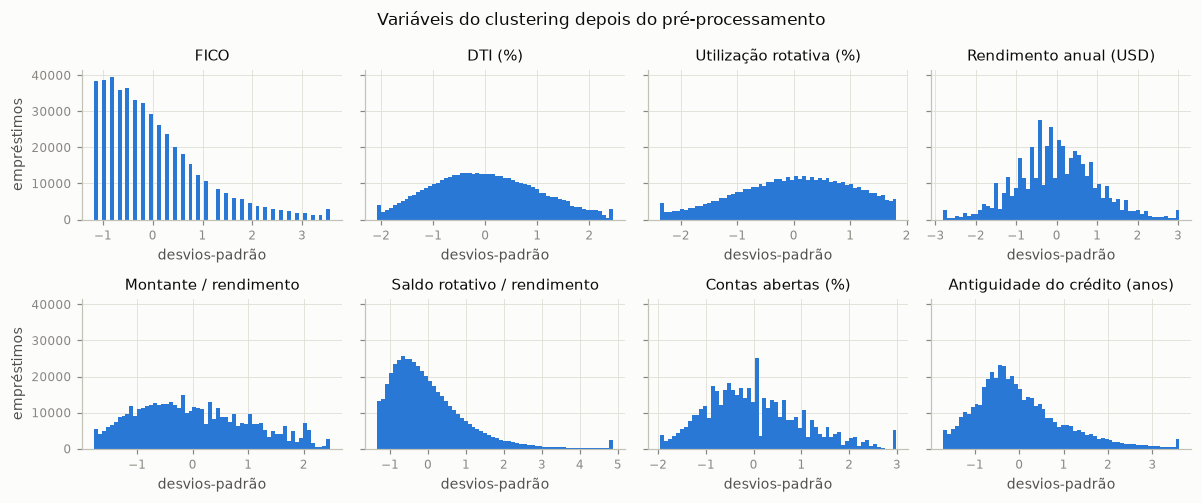

In [3]:
pipeline = profiles.pipeline()
X = pipeline.fit_transform(data[profiles.source_columns()])
print(f"Matriz do clustering: {X.shape[0]:,} x {X.shape[1]}, valores em falta: {int(X.isna().sum().sum())}")

check = pd.DataFrame({
    "assimetria antes": original[profiles.features].skew(),
    "assimetria depois": X.skew(),
    "média": X.mean(),
    "desvio": X.std(ddof=0),
}).rename(index=PROFILE_LABELS)
display(check.round(2))

fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for ax, column in zip(axes.ravel(), profiles.features):
    ax.hist(X[column], bins=60, color=CATEGORICAL[0])
    ax.set_title(PROFILE_LABELS[column])
    ax.set_xlabel("desvios-padrão")
for ax in axes[:, 0]:
    ax.set_ylabel("empréstimos")
fig.suptitle("Variáveis do clustering depois do pré-processamento")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_variaveis.png")
plt.show()

**Leitura.**

- A matriz final não tem valores em falta, e todas as colunas têm média 0 e desvio 1: as 8 variáveis pesam o mesmo na distância.
- **O log resolveu o rendimento:** a assimetria passou de 29,6 para 0,1.
- **O saldo rotativo / rendimento continua com cauda à direita** (assimetria 4,2 → 1,6). A barra isolada a 4,9 desvios são os 2 331 empréstimos (0,5%) presos no limite do *clipping*, com saldo rotativo acima de 1,07 vezes o rendimento. Se aparecer um grupo pequeno só com estes empréstimos, é por causa desta cauda; a coluna `smallest_cluster_pct` das grelhas serve para o detetar. Não se aplicou log a este rácio: `log(1 + x)` quase não muda valores abaixo de 1 (a assimetria só desceria para 1,05) e o *clipping* já limita o extremo.
- **O FICO é discreto** (passos de 5 pontos) e concentrado entre 660 e 720, com cauda à direita.
- As barras nos extremos de quase todas as variáveis são o *clipping*: os 0,5% de cada lado ficam acumulados no limite. Os "pentes" no rendimento vêm de valores redondos declarados (50 000, 60 000 USD).

### Correlações

Na distância euclidiana, duas variáveis muito correlacionadas medem quase a mesma coisa e essa dimensão do perfil conta a dobrar. Uma correlação de Spearman (ordens) acima de 0,8 seria razão para tirar uma das duas.

Maior |rho| entre duas variáveis: 0.41 (Montante / rendimento / Saldo rotativo / rendimento)


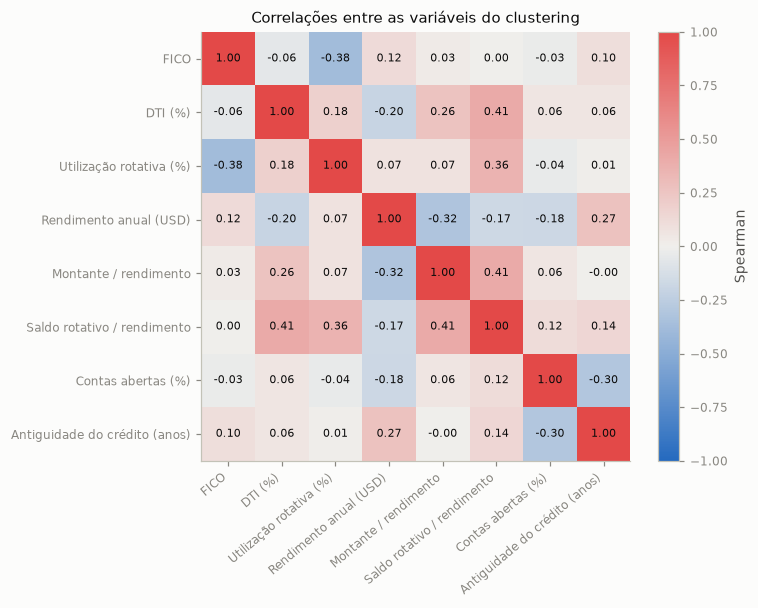

In [4]:
corr = X.corr(method="spearman").rename(index=PROFILE_LABELS, columns=PROFILE_LABELS)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Maior |rho| entre duas variáveis: {upper.abs().max():.2f} "
      f"({upper.abs().idxmax()[0]} / {upper.abs().idxmax()[1]})")

fig, ax = plt.subplots(figsize=(7, 5.6))
image = ax.imshow(corr, cmap=DIVERGING_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Spearman")
ax.set_title("Correlações entre as variáveis do clustering")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_correlacoes.png")
plt.show()

**Leitura.**

- A maior correlação é 0,41 (montante / rendimento com saldo rotativo / rendimento, e DTI com saldo rotativo / rendimento). Nenhum par passa de 0,8, por isso as 8 variáveis ficam: cada uma acrescenta informação e nenhuma dimensão do perfil conta a dobrar.
- FICO e utilização rotativa: -0,38. É o esperado, porque a utilização do crédito entra no cálculo do FICO.
- Rendimento e montante / rendimento: -0,32, porque o rendimento é o denominador.
- Contas abertas (%) e antiguidade: -0,30. Quem tem um historial longo acumulou contas já fechadas.
- Com correlações tão fracas, não há razão para reduzir a dimensão (PCA) antes do clustering. A PCA fica só para desenhar os grupos.

### Composição no tempo

O clustering junta oito anos de empréstimos. Se a população mudou muito, os grupos podem refletir os anos em vez de perfis de mutuário.

In [5]:
year = data["issue_d"].dt.year.rename("ano")
by_year = original[profiles.features].groupby(year).median().rename(columns=PROFILE_LABELS)
by_year.insert(0, "% dos empréstimos", (100 * year.value_counts(normalize=True).sort_index()).round(1))
by_year.insert(0, "empréstimos", year.value_counts().sort_index())
by_year.round(2)

,empréstimos,% dos empréstimos,FICO,DTI (%),Utilização rotativa (%),Rendimento anual (USD),Montante / rendimento,Saldo rotativo / rendimento,Contas abertas (%),Antiguidade do crédito (anos)
ano,,,,,,,,,,
2007,603,0.1,680.0,10.00,48.1,50000.0,0.14,0.11,58.33,8.17
2008,2388,0.5,690.0,13.10,49.5,52529.5,0.14,0.18,50.00,11.00
2009,5280,1.1,710.0,12.60,44.4,57000.0,0.15,0.16,46.43,11.58
2010,12532,2.7,710.0,13.24,48.8,57996.0,0.16,0.15,43.95,12.33
2011,21709,4.7,710.0,13.92,51.5,60000.0,0.17,0.16,43.59,12.92
2012,53334,11.4,695.0,16.48,61.0,60000.0,0.20,0.20,47.06,13.33
2013,134767,28.9,690.0,16.89,60.3,64000.0,0.21,0.21,46.67,14.50
2014,235511,50.5,685.0,17.62,56.3,65000.0,0.21,0.19,46.67,15.17


**Leitura.**

- **2013 e 2014 têm 79,4% dos empréstimos** (só 2014 tem 50,5%), e 2007–2011 juntos têm 9,1%. Os grupos vão descrever sobretudo os mutuários de 2013–2014. Não se pondera nem se reamostra por ano: o objetivo é descrever os mutuários que a LendingClub financiou, e esses são, na maioria, dos últimos anos.
- **A população mudou:** o DTI mediano subiu de 10 (2007) para 17,6 (2014), a utilização rotativa passou de 44–52% (até 2011) para 56–61% (a partir de 2012) e a antiguidade do crédito de 8 para 15 anos. O FICO mediano subiu para 710 em 2009–2011 e voltou a descer para 685 em 2014.
- **Consequência:** um grupo pode juntar sobretudo empréstimos de um período (ex.: DTI baixo e historial curto, típico dos primeiros anos) em vez de um tipo de mutuário. Para o verificar, cada grupo vai ter a sua distribuição por ano e a estabilidade compara grupos ajustados em 2007–2012 e em 2013–2014. Isto responde ao pedido do enunciado de discutir a mudança temporal (*"temporal change"*).